NAME    : Aleti Sanay Goud

BRANCH  : CSE(AI&ML)-B

ROLL.NO : 24911A6666

BATCH.NO: 07

ESSENTIALS OF MACHINE LEARNING, CASE STUDY ON NOTFLIX MOVIES AND SERIES




**About Dataset**
Each row has one title (movie or series) available on Netflix, with metadata like cast, director, country of production, genre tags, and a short synopsis.

Movies: 6,131 (~70%) | TV Shows: 2,676 (~30%) | Release years span 1925 → 2021 | Top producing countries: United States (2,818), India (972), UK (419), Japan (245), South Korea (199) | No exact duplicate rows or duplicate titles found







In [ ]:
from google.colab import drive


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/netflix_titles.csv')

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/netflix_titles.csv')

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing categorical values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna('Unknown')

# Convert categorical columns into numerical values
le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

# Display the processed data
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,0,0,1975,2295,7246,603,1711,2020,7,210,274,2577
1,1111,1,1091,4303,409,426,1706,2021,11,110,414,1762
2,2222,1,2651,2105,6296,736,1706,2021,11,0,242,7341
3,3333,1,3506,4303,7246,736,1706,2021,11,0,297,3617
4,4444,1,3861,4303,4815,251,1706,2021,11,110,393,4416


In [ ]:
# Separate input features and target variable
X = df.drop('type', axis=1)
y = df['type']

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7045, 11)
Testing data: (1762, 11)


KNN ALGORITHM

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Build the KNN model
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

print("KNN model created successfully")

KNN model created successfully


In [ ]:
# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully")

Model training completed successfully


In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,0,0,1975,2295,7246,603,1711,2020,7,210,274,2577
1,1111,1,1091,4303,409,426,1706,2021,11,110,414,1762
2,2222,1,2651,2105,6296,736,1706,2021,11,0,242,7341
3,3333,1,3506,4303,7246,736,1706,2021,11,0,297,3617
4,4444,1,3861,4303,4815,251,1706,2021,11,110,393,4416


In [ ]:
# Predict the output for testing data
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head())

print("Predicted values:")
print(y_pred[:5])

Actual values:
4970    0
3362    0
5494    1
1688    1
1349    1
Name: type, dtype: int64
Predicted values:
[1 0 1 1 0]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

# Display the classification report
print(classification_report(y_test, y_pred))

Model Accuracy: 0.8898978433598184
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      1214
           1       0.83      0.81      0.82       548

    accuracy                           0.89      1762
   macro avg       0.87      0.87      0.87      1762
weighted avg       0.89      0.89      0.89      1762



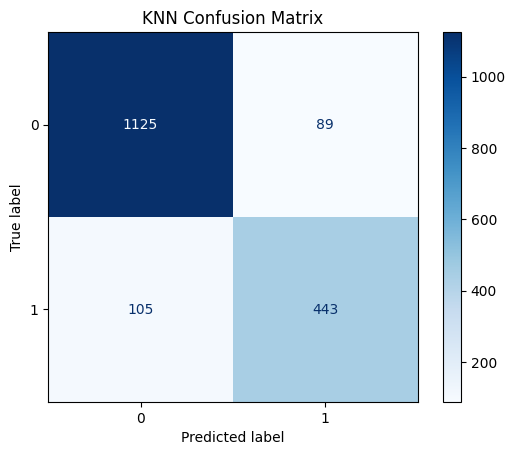

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.show()

In [ ]:
# Create a new sample using the training columns
new_sample = X.iloc[[0]].copy()

# Predict the class
prediction = model.predict(new_sample)

# Display the result
print("Predicted Netflix Title Type:", prediction[0])

Predicted Netflix Title Type: 0


SVM MODEL

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- 1. SVM Linear Kernel ---
print("=== SVM Linear Kernel ===")
svm_linear = make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=42))
svm_linear.fit(X_train, y_train)
y_pred_linear = svm_linear.predict(X_test)
print("Linear Accuracy:", accuracy_score(y_test, y_pred_linear))
print("Classification Report:")
print(classification_report(y_test, y_pred_linear))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_linear))
print("Predict New Sample:", svm_linear.predict(new_sample)[0])
print("\n" + "="*40 + "\n")

# --- 2. SVM RBF Kernel ---
print("=== SVM RBF Kernel ===")
svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
print("RBF Accuracy:", accuracy_score(y_test, y_pred_rbf))
print("Classification Report:")
print(classification_report(y_test, y_pred_rbf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rbf))
print("Predict New Sample:", svm_rbf.predict(new_sample)[0])
print("\n" + "="*40 + "\n")

# --- 3. SVM Poly Kernel ---
print("=== SVM Poly Kernel ===")
svm_poly = make_pipeline(StandardScaler(), SVC(kernel='poly', degree=3, random_state=42))
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)
print("Poly Accuracy:", accuracy_score(y_test, y_pred_poly))
print("Classification Report:")
print(classification_report(y_test, y_pred_poly))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_poly))
print("Predict New Sample:", svm_poly.predict(new_sample)[0])

=== SVM Linear Kernel ===
Linear Accuracy: 0.8893303064699205
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      1214
           1       0.82      0.82      0.82       548

    accuracy                           0.89      1762
   macro avg       0.87      0.87      0.87      1762
weighted avg       0.89      0.89      0.89      1762

Confusion Matrix:
[[1118   96]
 [  99  449]]
Predict New Sample: 0


=== SVM RBF Kernel ===
RBF Accuracy: 0.916572077185017
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      1214
           1       0.86      0.87      0.87       548

    accuracy                           0.92      1762
   macro avg       0.90      0.90      0.90      1762
weighted avg       0.92      0.92      0.92      1762

Confusion Matrix:
[[1137   77]
 [  70  478]]
Predict New Sample: 0


=== SVM Poly Kernel ===
Poly Accuracy: 0.8972

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

linear_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='linear')
)

print("SVM Linear Kernel model created successfully")

SVM Linear Kernel model created successfully


In [ ]:
linear_model.fit(X_train, y_train)

print("Linear SVM model trained successfully")

Linear SVM model trained successfully


In [ ]:
y_pred_linear = linear_model.predict(X_test)

print("Actual values:", y_test.iloc[:5].tolist())
print("Predicted values:", y_pred_linear[:5].tolist())

Actual values: [0, 0, 1, 1, 1]
Predicted values: [0, 0, 1, 1, 1]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_linear = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuracy:", accuracy_linear)
print(classification_report(y_test, y_pred_linear))

Linear SVM Accuracy: 0.8893303064699205
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      1214
           1       0.82      0.82      0.82       548

    accuracy                           0.89      1762
   macro avg       0.87      0.87      0.87      1762
weighted avg       0.89      0.89      0.89      1762



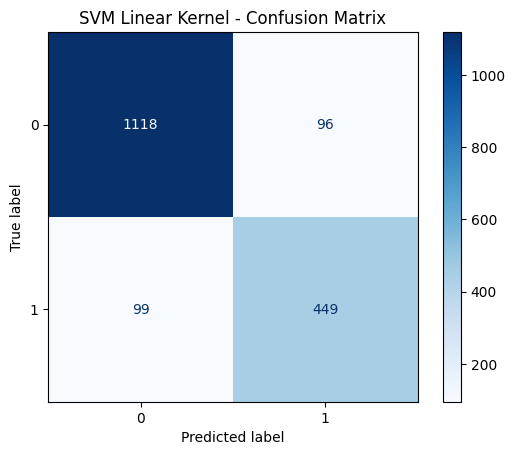

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_linear,
    display_labels=linear_model.classes_,
    cmap='Blues'
)

plt.title("SVM Linear Kernel - Confusion Matrix")
plt.show()

In [ ]:
new_sample = X_test.iloc[[0]]

prediction_linear = linear_model.predict(new_sample)

print("Predicted class:", prediction_linear[0])

Predicted class: 0


In [ ]:
rbf_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)

print("SVM RBF Kernel model created successfully")

SVM RBF Kernel model created successfully


In [ ]:
rbf_model.fit(X_train, y_train)

print("RBF SVM model trained successfully")

RBF SVM model trained successfully


In [ ]:
y_pred_rbf = rbf_model.predict(X_test)

print("Actual values:", y_test.iloc[:5].tolist())
print("Predicted values:", y_pred_rbf[:5].tolist())

Actual values: [0, 0, 1, 1, 1]
Predicted values: [0, 0, 1, 1, 0]


In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("RBF SVM Accuracy:", accuracy_rbf)
print(classification_report(y_test, y_pred_rbf))

RBF SVM Accuracy: 0.916572077185017
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      1214
           1       0.86      0.87      0.87       548

    accuracy                           0.92      1762
   macro avg       0.90      0.90      0.90      1762
weighted avg       0.92      0.92      0.92      1762



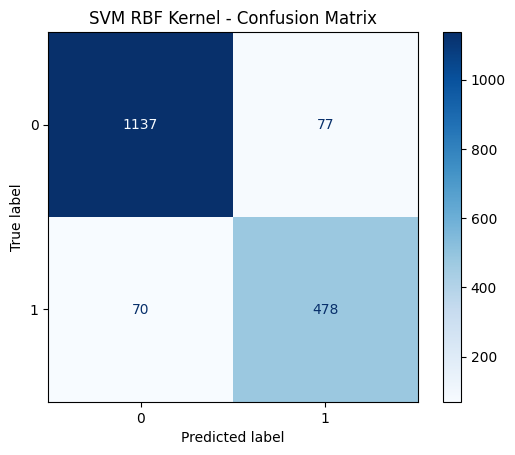

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rbf,
    display_labels=rbf_model.classes_,
    cmap='Blues'
)

plt.title("SVM RBF Kernel - Confusion Matrix")
plt.show()

In [ ]:
new_sample = X_test.iloc[[0]]

prediction_rbf = rbf_model.predict(new_sample)

print("Predicted class:", prediction_rbf[0])

Predicted class: 0


In [ ]:
poly_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='poly', degree=3)
)

print("SVM Polynomial Kernel model created successfully")

SVM Polynomial Kernel model created successfully


In [ ]:
poly_model.fit(X_train, y_train)

print("Polynomial SVM model trained successfully")

Polynomial SVM model trained successfully


In [ ]:
y_pred_poly = poly_model.predict(X_test)

print("Actual values:", y_test.iloc[:5].tolist())
print("Predicted values:", y_pred_poly[:5].tolist())

Actual values: [0, 0, 1, 1, 1]
Predicted values: [0, 0, 1, 1, 0]


In [ ]:
accuracy_poly = accuracy_score(y_test, y_pred_poly)

print("Polynomial SVM Accuracy:", accuracy_poly)
print(classification_report(y_test, y_pred_poly))

Polynomial SVM Accuracy: 0.8972758229284904
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      1214
           1       0.87      0.78      0.83       548

    accuracy                           0.90      1762
   macro avg       0.89      0.87      0.88      1762
weighted avg       0.90      0.90      0.90      1762



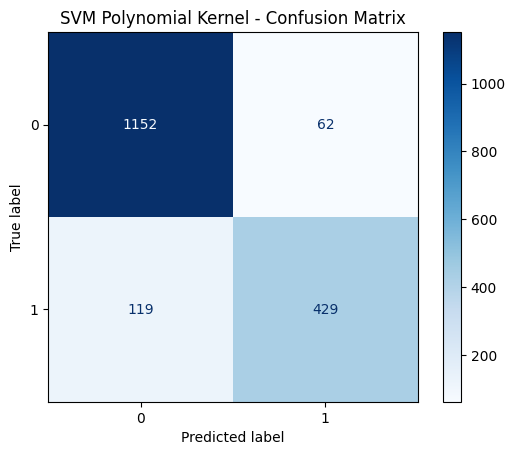

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_poly,
    display_labels=poly_model.classes_,
    cmap='Blues'
)

plt.title("SVM Polynomial Kernel - Confusion Matrix")
plt.show()

In [ ]:
new_sample = X_test.iloc[[0]]

prediction_poly = poly_model.predict(new_sample)

print("Predicted class:", prediction_poly[0])

Predicted class: 0


In [ ]:
new_sample = X_test.iloc[[0]]

prediction_poly = poly_model.predict(new_sample)

print("Predicted class:", prediction_poly[0])

Predicted class: 0


In [ ]:
print("Linear SVM Accuracy:", accuracy_linear)
print("RBF SVM Accuracy:", accuracy_rbf)
print("Polynomial SVM Accuracy:", accuracy_poly)

Linear SVM Accuracy: 0.8893303064699205
RBF SVM Accuracy: 0.916572077185017
Polynomial SVM Accuracy: 0.8972758229284904


DECISSION TREE

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create the decision tree model using entropy
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42,
    max_depth=5
)

print("Decision Tree model using ID3-style entropy created successfully")

Decision Tree model using ID3-style entropy created successfully


In [ ]:
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully")

Decision Tree model trained successfully


In [ ]:
y_pred_dt = dt_model.predict(X_test)

print("Actual values:", y_test.iloc[:5].tolist())
print("Predicted values:", y_pred_dt[:5].tolist())

Actual values: [0, 0, 1, 1, 1]
Predicted values: [0, 0, 1, 1, 1]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9824063564131669

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1214
           1       0.98      0.97      0.97       548

    accuracy                           0.98      1762
   macro avg       0.98      0.98      0.98      1762
weighted avg       0.98      0.98      0.98      1762



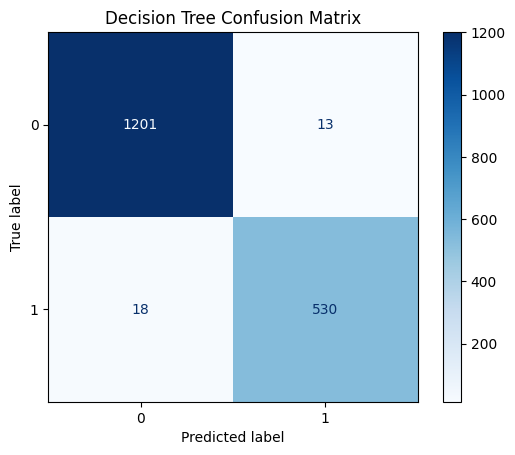

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=dt_model.classes_,
    cmap='Blues'
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [ ]:
# Select one sample from the test dataset
new_sample = X_test.iloc[[0]]

# Predict the class
prediction = dt_model.predict(new_sample)

print("Predicted class:", prediction[0])

Predicted class: 0


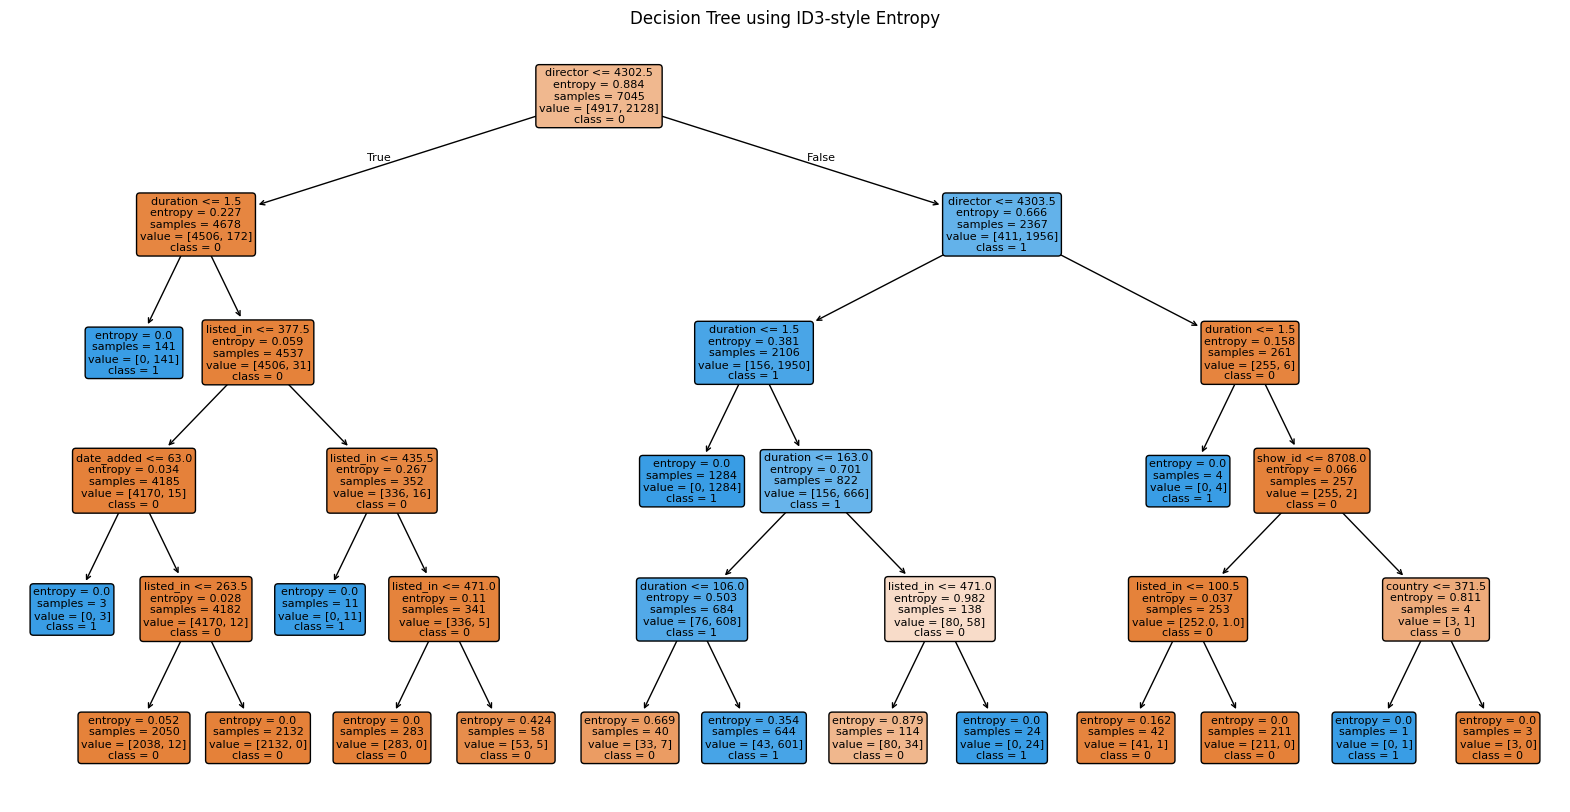

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=[str(c) for c in dt_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree using ID3-style Entropy")
plt.show()